In [1]:
# ── Google Drive Mount ────────────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive', force_remount=False)
print("✅ Google Drive mounted")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive mounted


In [2]:
# ── Google Drive Paths ────────────────────────────────────────────────────────
GDRIVE_ROOT   = '/content/drive/My Drive/MIS_ETP'
SIM_DATA_DIR  = '/content/drive/My Drive/MIS_ETP/data/CNN_Elasto_data_2020'
PHANTOM_DIR   = '/content/drive/My Drive/MIS_ETP/data/TUFFC_2022_Bi_Directional_elasto'
PROCESSED_DIR = '/content/drive/My Drive/MIS_ETP/data/processed'
WEIGHTS_DIR   = '/content/drive/My Drive/MIS_ETP/data/processed'
OUT_DIR       = '/content/drive/My Drive/MIS_ETP/data/processed'

import os
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(WEIGHTS_DIR,   exist_ok=True)
print(f"✅ Paths configured:")
print(f"   SIM_DATA_DIR  → {SIM_DATA_DIR}")
print(f"   PHANTOM_DIR   → {PHANTOM_DIR}")
print(f"   PROCESSED_DIR → {PROCESSED_DIR}")
print(f"   WEIGHTS_DIR   → {WEIGHTS_DIR}")


✅ Paths configured:
   SIM_DATA_DIR  → /content/drive/My Drive/MIS_ETP/data/CNN_Elasto_data_2020
   PHANTOM_DIR   → /content/drive/My Drive/MIS_ETP/data/TUFFC_2022_Bi_Directional_elasto
   PROCESSED_DIR → /content/drive/My Drive/MIS_ETP/data/processed
   WEIGHTS_DIR   → /content/drive/My Drive/MIS_ETP/data/processed


In [3]:
# Paths are configured in the cell above (Google Drive paths)
import os, glob, torch, numpy as np, json
npz_files = sorted(glob.glob(os.path.join(PROCESSED_DIR, '*.npz')))
if not npz_files:
    raise RuntimeError(f'No processed data found in {PROCESSED_DIR}. Run Notebook 01 first.')
print(f'✅ Found {len(npz_files)} processed .npz files.')


✅ Found 42 processed .npz files.


# 🧠 Phase 2A: CNN-LSTM Pre-Training on Simulation Data

**Dataset Used:** Dataset 1 — `ultrasound-elastography-simulation-database` (processed .npz from Phase 1)

**Objective:** Train the CNN-LSTM architecture from scratch on mathematically clean simulated data.  
This teaches the model **fundamental physics of wave propagation and tissue mechanics** before domain adaptation.

**Pipeline:**
1. DataLoader for processed `.npz` simulation files
2. U-Net CNN Encoder (spatial feature extractor)
3. Bidirectional LSTM Temporal Tracker (displacement field)
4. 3-Class Classification Head (Benign / Precancerous / Malignant)
5. Physics-Informed Loss: LNCC + Spatio-temporal TV + Focal Loss
6. ADMM Optimization Loop (smooth + non-smooth sub-problems)
7. Training loop with checkpointing

> **Integrates Syllabus Unit 2:** SGD, Loss Functions, Matrix Splitting, Proximal Algorithms, ADMM

In [5]:
import os
import glob
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings
import json

warnings.filterwarnings('ignore')
torch.manual_seed(42)
np.random.seed(42)

# ── Device configuration ──────────────────────────────────────────────────────
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'🖥  Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'   GPU: {torch.cuda.get_device_name(0)}')
    print(f'   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

# ── Paths ─────────────────────────────────────────────────────────────────────
# PROCESSED_DIR set in paths cell above
# WEIGHTS_DIR set in paths cell above

# ── Hyperparameters ───────────────────────────────────────────────────────────
HPARAMS = {
    # ── Architecture ─────────────────────────────────────────────────────────
    'cnn_channels'  : [1, 16, 32, 64, 128],  # U-Net encoder channel progression
    'lstm_hidden'   : 256,                    # Bi-LSTM hidden units per direction
    'lstm_layers'   : 2,                      # Stacked LSTM layers
    'n_classes'     : 3,                      # Benign / Precancerous / Malignant
    'patch_size'    : 64,                     # Spatial patch size (H = W)
    'n_frames'      : 5,                      # Temporal sequence length T

    # ── Physics-Informed Loss ─────────────────────────────────────────────────
    'lncc_win'      : 9,                      # LNCC sliding window size
    'tv_lambda'     : 0.05,                   # Weight for spatio-temporal TV term
    'focal_gamma'   : 2.0,                    # Focal loss focusing parameter γ
    'class_weights' : None,                   # Per-class loss weights (None = uniform)

    # ── ADMM Optimizer ────────────────────────────────────────────────────────
    'lr_sgd'        : 1e-3,                   # SGD learning rate (θ-step)
    'momentum'      : 0.9,                    # SGD momentum
    'weight_decay'  : 1e-4,                   # L2 regularisation
    'admm_rho'      : 0.1,                    # ADMM penalty parameter ρ
    'admm_inner'    : 3,                      # ADMM inner iterations per batch

    # ── Training ──────────────────────────────────────────────────────────────
    'n_epochs'      : 50,                     # Total training epochs
    'batch_size'    : 8,                      # DataLoader batch size
}

for k, v in HPARAMS.items():
    print(f'   {k:20s}: {v}')

🖥  Device: cuda
   GPU: Tesla T4
   VRAM: 15.6 GB
   cnn_channels        : [1, 16, 32, 64, 128]
   lstm_hidden         : 256
   lstm_layers         : 2
   n_classes           : 3
   patch_size          : 64
   n_frames            : 5
   lncc_win            : 9
   tv_lambda           : 0.05
   focal_gamma         : 2.0
   class_weights       : None
   lr_sgd              : 0.001
   momentum            : 0.9
   weight_decay        : 0.0001
   admm_rho            : 0.1
   admm_inner          : 3
   n_epochs            : 50
   batch_size          : 8


## 1. Dataset & DataLoader

In [12]:
if not npz_files:
    raise RuntimeError(f'No processed data found in {PROCESSED_DIR}. Please run Notebook 01 first.')

# ── ElastographyDataset ───────────────────────────────────────────────────────
import re

def infer_label_from_filename(fname: str) -> int:
    """
    Infer 3-class label from filename conventions used in simulation datasets.
      0 = Benign        (default for simulation — no pathology marker)
      1 = Precancerous  ('pre', 'dysplasia', 'grade1')
      2 = Malignant     ('mal', 'cancer', 'grade2', 'grade3', 'tumor')
    """
    name = os.path.basename(fname).lower()
    if re.search(r'(malig|cancer|tumor|grade[23])', name):
        return 2
    elif re.search(r'(pre|dysplasia|grade1)', name):
        return 1
    return 0   # benign / simulation default


class ElastographyDataset(Dataset):
    """
    Loads processed .npz files (output of Notebook 01).

    Each .npz contains:
        rf_clean     : (D, W, F)          — DMD-cleaned RF stack
        rf_augmented : (n_aug, D, W, F)   — domain-randomized variants

    Returns: (frames, label)
        frames : (n_frames, 1, patch_size, patch_size)  float32 tensor
        label  : int scalar (0=Benign, 1=Precancerous, 2=Malignant)
    """
    def __init__(
        self,
        npz_files : list,
        n_frames  : int = 5,
        patch_size: int = 64,
        use_augmented: bool = True,
        augment   : bool = True,
    ):
        self.n_frames   = n_frames
        self.patch_size = patch_size
        self.augment    = augment

        self.samples = []   # list of (npz_path, aug_idx_or_None, label)

        for fpath in npz_files:
            label = infer_label_from_filename(fpath)
            # Always include the clean version
            self.samples.append((fpath, None, label))
            # Optionally include augmented variants
            if use_augmented:
                try:
                    data = np.load(fpath, allow_pickle=False)
                    if 'rf_augmented' in data:
                        n_aug = data['rf_augmented'].shape[0]
                        for i in range(n_aug):
                            self.samples.append((fpath, i, label))
                except Exception:
                    pass

    def __len__(self):
        return len(self.samples)

    def _load_rf(self, fpath: str, aug_idx) -> np.ndarray:
        """Returns RF stack as float32 array shaped (D, W, F)."""
        data = np.load(fpath, allow_pickle=False)
        if aug_idx is not None and 'rf_augmented' in data:
            rf = data['rf_augmented'][aug_idx]          # (D, W, F)
        else:
            rf = data['rf_clean']                       # (D, W, F)
        return rf.astype(np.float32)

    def _extract_patch(self, rf: np.ndarray) -> np.ndarray:
        """
        Crop a random (or centre) patch_size × patch_size region from (D, W).
        Returns (patch_size, patch_size).
        """
        D, W = rf.shape
        ps   = self.patch_size
        if D < ps or W < ps:
            # Upscale if the frame is smaller than patch_size
            from PIL import Image
            img = Image.fromarray(rf)
            img = img.resize((max(W, ps), max(D, ps)), Image.BILINEAR)
            rf  = np.array(img)
            D, W = rf.shape

        if self.augment:
            d0 = np.random.randint(0, D - ps + 1)
            w0 = np.random.randint(0, W - ps + 1)
        else:
            d0 = (D - ps) // 2
            w0 = (W - ps) // 2

        return rf[d0:d0+ps, w0:w0+ps]

    def __getitem__(self, idx):
        fpath, aug_idx, label = self.samples[idx]
        rf = self._load_rf(fpath, aug_idx)   # (D, W, F)

        D, W, F = rf.shape
        T       = self.n_frames

        # ── Sample T consecutive frames ───────────────────────────────────────
        if F < T:
            # Pad by repeating last frame
            pad  = np.repeat(rf[:, :, -1:], T - F, axis=2)
            rf   = np.concatenate([rf, pad], axis=2)
            F    = T
        if self.augment and F > T:
            t0 = np.random.randint(0, F - T + 1)
        else:
            t0 = (F - T) // 2
        rf_seq = rf[:, :, t0 : t0 + T]      # (D, W, T)

        # ── Extract spatial patch per frame ───────────────────────────────────
        frames = []
        for t in range(T):
            patch = self._extract_patch(rf_seq[:, :, t])  # (ps, ps)
            frames.append(patch)
        frames = np.stack(frames)   # (T, ps, ps)

        # ── Normalize per-sample to [0, 1] ────────────────────────────────────
        mn, mx = frames.min(), frames.max()
        if mx > mn:
            frames = (frames - mn) / (mx - mn + 1e-8)

        # ── To tensor: (T, 1, H, W) ───────────────────────────────────────────
        frames_t = torch.from_numpy(frames).unsqueeze(1)   # (T, 1, H, W)

        return frames_t, torch.tensor(label, dtype=torch.long)


# ── Build DataLoaders ─────────────────────────────────────────────────────────
full_dataset = ElastographyDataset(
    npz_files  = npz_files,
    n_frames   = HPARAMS['n_frames'],
    patch_size = HPARAMS['patch_size'],
    use_augmented = True,
    augment    = True,
)

val_frac  = 0.15
val_size  = max(1, int(len(full_dataset) * val_frac))
train_size = len(full_dataset) - val_size

train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)
# Disable spatial augmentation on the val split
val_dataset.dataset.augment = False

train_loader = DataLoader(
    train_dataset,
    batch_size  = HPARAMS['batch_size'],
    shuffle     = True,
    num_workers = 2,
    pin_memory  = True,
    drop_last   = True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size  = HPARAMS['batch_size'],
    shuffle     = False,
    num_workers = 2,
    pin_memory  = True,
)

print(f'✅ Dataset ready')
print(f'   Total samples : {len(full_dataset)}')
print(f'   Train samples : {len(train_dataset)}')
print(f'   Val   samples : {len(val_dataset)}')
print(f'   Train batches : {len(train_loader)}')

# ── Sanity-check one batch ────────────────────────────────────────────────────
x_sample, y_sample = next(iter(train_loader))
print(f'\n   Batch frames shape : {x_sample.shape}')  # (B, T, 1, H, W)
print(f'   Batch labels shape : {y_sample.shape}')   # (B,)
print(f'   Label distribution : {dict(zip(*np.unique(y_sample.numpy(), return_counts=True)))}')
print(f'   Value range        : [{x_sample.min():.3f}, {x_sample.max():.3f}]')


✅ Dataset ready
   Total samples : 168
   Train samples : 143
   Val   samples : 25
   Train batches : 17

   Batch frames shape : torch.Size([8, 5, 1, 64, 64])
   Batch labels shape : torch.Size([8])
   Label distribution : {np.int64(0): np.int64(8)}
   Value range        : [0.000, 1.000]


## 2. Architecture — CNN-LSTM Hybrid Model

In [7]:
# ─────────────────────────────────────────────────────────────────────────────
#  U-Net Encoder Block (Spatial Feature Extractor)
# ─────────────────────────────────────────────────────────────────────────────
class ConvBlock(nn.Module):
    """Double convolution block with BatchNorm and GELU activation."""
    def __init__(self, in_ch: int, out_ch: int, dropout: float = 0.1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
            nn.Dropout2d(dropout)
        )
    def forward(self, x):
        return self.block(x)


class UNetEncoder(nn.Module):
    """
    Modified U-Net encoder: extracts deep speckle features from RF frames.
    Outputs: (B, feat_dim) global feature vector per frame.
    """
    def __init__(self, channels: list = [1, 16, 32, 64, 128]):
        super().__init__()
        self.encoders = nn.ModuleList()
        self.pools    = nn.ModuleList()

        for i in range(len(channels) - 1):
            self.encoders.append(ConvBlock(channels[i], channels[i+1]))
            if i < len(channels) - 2:
                self.pools.append(nn.MaxPool2d(2, 2))

        self.feat_dim = channels[-1]  # output feature depth
        # Global average + max pooling for spatial aggregation
        self.global_pool = nn.AdaptiveAvgPool2d(1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args: x: (B, 1, H, W)
        Returns: feats: (B, feat_dim)
        """
        for i, enc in enumerate(self.encoders):
            x = enc(x)
            if i < len(self.pools):
                x = self.pools[i](x)
        feats = self.global_pool(x).squeeze(-1).squeeze(-1)  # (B, feat_dim)
        return feats


# ─────────────────────────────────────────────────────────────────────────────
#  Full CNN-LSTM Model
# ─────────────────────────────────────────────────────────────────────────────
class CNNLSTMElastography(nn.Module):
    """
    Physics-informed CNN-LSTM for ultrasound elastography tumor grading.

    Architecture:
        Frame_t → CNN Encoder → feat_t  (spatial features)
        [feat_1, ..., feat_T] → Bi-LSTM → h_T  (temporal deformation tracking)
        h_T → Displacement Head → strain_map  (2D displacement field)
        h_T → Classification Head → [P_Benign, P_Precancerous, P_Malignant]

    Input:  (B, T, 1, H, W)  — batch of RF frame sequences
    Output: (logits, displacement)
        logits      : (B, n_classes)
        displacement: (B, T, H, W)  — dense 2D displacement field
    """

    def __init__(
        self,
        cnn_channels : list = [1, 16, 32, 64, 128],
        lstm_hidden  : int = 256,
        lstm_layers  : int = 2,
        n_classes    : int = 3,
        patch_size   : int = 64,
        dropout      : float = 0.3
    ):
        super().__init__()
        self.patch_size  = patch_size
        self.lstm_hidden = lstm_hidden

        # ── Spatial Extractor ─────────────────────────────────────────────────
        self.cnn = UNetEncoder(channels=cnn_channels)
        feat_dim = cnn_channels[-1]

        # ── Temporal Tracker ──────────────────────────────────────────────────
        self.lstm = nn.LSTM(
            input_size=feat_dim,
            hidden_size=lstm_hidden,
            num_layers=lstm_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if lstm_layers > 1 else 0.0
        )
        lstm_out_dim = lstm_hidden * 2  # bidirectional

        # ── Classification Head ───────────────────────────────────────────────
        self.classifier = nn.Sequential(
            nn.LayerNorm(lstm_out_dim),
            nn.Linear(lstm_out_dim, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 64),
            nn.GELU(),
            nn.Linear(64, n_classes)
        )

        # ── Displacement (Strain Map) Head ────────────────────────────────────
        # Decodes LSTM output back to spatial displacement field
        reduced_spatial = patch_size // (2 ** (len(cnn_channels) - 2))
        self.disp_head = nn.Sequential(
            nn.Linear(lstm_out_dim, reduced_spatial * reduced_spatial),
            nn.GELU()
        )
        self.disp_upsample = nn.Upsample(
            size=(patch_size, patch_size), mode='bilinear', align_corners=False
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, (nn.BatchNorm2d, nn.LayerNorm)):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor):
        """
        Args:
            x: (B, T, 1, H, W)
        Returns:
            logits      : (B, n_classes)
            displacement: (B, T, H, W)
        """
        B, T, C, H, W = x.shape
        reduced = H // (2 ** (len([16,32,64,128]) - 1))

        # ── CNN: process each frame independently ─────────────────────────────
        x_flat = x.view(B * T, C, H, W)         # (B*T, 1, H, W)
        feats  = self.cnn(x_flat)                # (B*T, feat_dim)
        feats  = feats.view(B, T, -1)            # (B, T, feat_dim)

        # ── LSTM: temporal deformation tracking ───────────────────────────────
        lstm_out, (h_n, _) = self.lstm(feats)   # lstm_out: (B, T, lstm_out_dim)

        # Use concatenated final hidden states (both directions)
        h_final = torch.cat([h_n[-2], h_n[-1]], dim=-1)  # (B, lstm_out_dim)

        # ── Classification ────────────────────────────────────────────────────
        logits = self.classifier(h_final)        # (B, n_classes)

        # ── Displacement field (per timestep) ─────────────────────────────────
        disp_flat = self.disp_head(lstm_out.reshape(B * T, -1))  # (B*T, r*r)
        r = int(disp_flat.shape[-1] ** 0.5)
        disp_spatial = disp_flat.view(B * T, 1, r, r)
        disp_up = self.disp_upsample(disp_spatial)               # (B*T, 1, H, W)
        displacement = disp_up.view(B, T, H, W)                  # (B, T, H, W)

        return logits, displacement


# ── Instantiate model ─────────────────────────────────────────────────────────
model = CNNLSTMElastography(
    cnn_channels = HPARAMS['cnn_channels'],
    lstm_hidden  = HPARAMS['lstm_hidden'],
    lstm_layers  = HPARAMS['lstm_layers'],
    n_classes    = HPARAMS['n_classes'],
    patch_size   = HPARAMS['patch_size']
).to(DEVICE)

# Parameter count
total_params = sum(p.numel() for p in model.parameters())
train_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\n📐 Model Summary')
print(f'   Total parameters   : {total_params:,}')
print(f'   Trainable params   : {train_params:,}')

# Dry run
dummy = torch.randn(2, HPARAMS['n_frames'], 1,
                    HPARAMS['patch_size'], HPARAMS['patch_size']).to(DEVICE)
with torch.no_grad():
    logits_d, disp_d = model(dummy)
print(f'   Logits shape       : {logits_d.shape}')
print(f'   Displacement shape : {disp_d.shape}')
print('✅ Model instantiated')


📐 Model Summary
   Total parameters   : 2,769,171
   Trainable params   : 2,769,171
   Logits shape       : torch.Size([2, 3])
   Displacement shape : torch.Size([2, 5, 64, 64])
✅ Model instantiated


## 3. Physics-Informed Loss Functions

### 3.1 Local Normalized Cross-Correlation (LNCC)
Measures acoustic tracking fidelity between consecutive frames:
$$\text{LNCC}(u, v) = 1 - \frac{\sum_{\Omega} (u - \bar{u})(v - \bar{v})}{\sqrt{\sum_{\Omega}(u-\bar{u})^2 \cdot \sum_{\Omega}(v-\bar{v})^2}}$$

### 3.2 Spatio-Temporal Total Variation (TV)
Enforces physical continuity — tissue does not tear randomly:
$$\text{TV}(d) = \sum_{x,y,t} \sqrt{(\nabla_x d)^2 + (\nabla_y d)^2 + (\nabla_t d)^2}$$

### 3.3 Focal Loss
Addresses class imbalance (Precancerous is rare):
$$\text{FL}(p_t) = -\alpha_t(1-p_t)^\gamma \log(p_t)$$

In [8]:
class LNCCLoss(nn.Module):
    """
    Local Normalized Cross-Correlation Loss.
    Compares consecutive displacement frames.
    """
    def __init__(self, win: int = 9):
        super().__init__()
        self.win = win

    def forward(self, pred: torch.Tensor, target: torch.Tensor = None) -> torch.Tensor:
        """
        pred   : (B, T, H, W) predicted displacement field
        target : (B, T, H, W) reference (next frame RF as proxy)
        If target is None, uses consecutive frames from pred as self-supervision.
        """
        if target is None:
            if pred.shape[1] < 2:
                return torch.tensor(0.0, device=pred.device)
            u = pred[:, :-1, :, :]   # (B, T-1, H, W)
            v = pred[:, 1:,  :, :]   # (B, T-1, H, W)
        else:
            u, v = pred, target

        B, T_1, H, W = u.shape
        w = self.win
        pad = w // 2

        # Flatten temporal into batch
        u_flat = u.reshape(B * T_1, 1, H, W)
        v_flat = v.reshape(B * T_1, 1, H, W)

        # Local sums via average pooling
        kernel = torch.ones(1, 1, w, w, device=u.device) / (w * w)
        u_mean = F.conv2d(u_flat, kernel, padding=pad)
        v_mean = F.conv2d(v_flat, kernel, padding=pad)

        u_c = u_flat - u_mean
        v_c = v_flat - v_mean

        cross  = F.conv2d(u_c * v_c,   kernel, padding=pad)
        u_sq   = F.conv2d(u_c * u_c,   kernel, padding=pad)
        v_sq   = F.conv2d(v_c * v_c,   kernel, padding=pad)

        eps = 1e-8
        lncc = cross / (torch.sqrt(u_sq * v_sq) + eps)   # in [-1, 1]
        return 1.0 - lncc.mean()   # minimize → maximize correlation


class SpatioTemporalTVLoss(nn.Module):
    """
    Spatio-Temporal Total Variation regularization.
    Enforces smooth, continuous displacement fields in x, y, t.
    """
    def forward(self, disp: torch.Tensor) -> torch.Tensor:
        """
        disp: (B, T, H, W)
        """
        # Spatial gradients
        dx = torch.abs(disp[:, :, 1:, :]  - disp[:, :, :-1, :])  # ∂/∂x
        dy = torch.abs(disp[:, :, :, 1:]  - disp[:, :, :, :-1])  # ∂/∂y
        # Temporal gradient
        dt = torch.abs(disp[:, 1:, :, :]  - disp[:, :-1, :, :])  # ∂/∂t

        tv_spatial  = (dx[:, :, :, :-1] + dy[:, :, :-1, :]).mean()
        tv_temporal = dt.mean()
        return tv_spatial + 0.5 * tv_temporal


class FocalLoss(nn.Module):
    """
    Focal Loss for multi-class classification with class imbalance.
    FL(p_t) = -α_t * (1 - p_t)^γ * log(p_t)
    """
    def __init__(
        self,
        gamma: float = 2.0,
        class_weights: list = None,
        n_classes: int = 3
    ):
        super().__init__()
        self.gamma = gamma
        if class_weights is not None:
            w = torch.tensor(class_weights, dtype=torch.float32)
        else:
            w = torch.ones(n_classes)
        self.register_buffer('alpha', w / w.sum())

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        """
        logits  : (B, n_classes)
        targets : (B,) integer labels
        """
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        p_t     = torch.exp(-ce_loss)                   # probability of correct class
        alpha_t = self.alpha[targets]                    # per-sample class weights
        focal   = alpha_t * (1 - p_t) ** self.gamma * ce_loss
        return focal.mean()


class PhysicsInformedLoss(nn.Module):
    """
    Combined physics-informed loss:
        L = L_LNCC + λ_tv * L_TV + L_focal
    """
    def __init__(
        self,
        lncc_win       : int   = 9,
        tv_lambda      : float = 0.05,
        focal_gamma    : float = 2.0,
        class_weights  : list  = None,
        n_classes      : int   = 3
    ):
        super().__init__()
        self.lncc_loss  = LNCCLoss(win=lncc_win)
        self.tv_loss    = SpatioTemporalTVLoss()
        self.focal_loss = FocalLoss(gamma=focal_gamma,
                                    class_weights=class_weights,
                                    n_classes=n_classes)
        self.tv_lambda  = tv_lambda

    def forward(
        self,
        logits      : torch.Tensor,
        displacement: torch.Tensor,
        targets     : torch.Tensor
    ):
        l_lncc  = self.lncc_loss(displacement)
        l_tv    = self.tv_loss(displacement)
        l_focal = self.focal_loss(logits, targets)

        total = l_lncc + self.tv_lambda * l_tv + l_focal
        return total, {'lncc': l_lncc.item(), 'tv': l_tv.item(), 'focal': l_focal.item()}


# ── Instantiate losses ────────────────────────────────────────────────────────
criterion = PhysicsInformedLoss(
    lncc_win     = HPARAMS['lncc_win'],
    tv_lambda    = HPARAMS['tv_lambda'],
    focal_gamma  = HPARAMS['focal_gamma'],
    class_weights= HPARAMS['class_weights'],
    n_classes    = HPARAMS['n_classes']
).to(DEVICE)

print('✅ Loss functions ready')

# Quick loss sanity check
with torch.no_grad():
    total_l, parts = criterion(logits_d, disp_d, torch.zeros(2, dtype=torch.long).to(DEVICE))
    print(f'  Dummy total loss: {total_l.item():.4f}  |  parts: {parts}')

✅ Loss functions ready
  Dummy total loss: 1.1565  |  parts: {'lncc': 0.11169946193695068, 'tv': 0.005891760811209679, 'focal': 1.0444564819335938}


## 4. ADMM Optimization Loop

Standard SGD cannot optimize the non-smooth TV loss directly.  
We split the problem using **ADMM (Alternating Direction Method of Multipliers)**:

$$\min_{\theta, z} \; L_{\text{smooth}}(\theta) + \lambda \|z\|_{TV} \quad \text{s.t.} \quad d(\theta) = z$$

**Augmented Lagrangian:**
$$\mathcal{L}_\rho = L_{\text{smooth}} + \lambda \|z\|_{TV} + u^T(d - z) + \frac{\rho}{2}\|d-z\|_2^2$$

**Updates:**
- *Sub-problem A (θ-update):* SGD on smooth terms (LNCC + Focal)
- *Sub-problem B (z-update):* Proximal operator (soft-thresholding for TV)
- *Dual update (u):* $u \leftarrow u + d - z$

In [9]:
def soft_threshold(x: torch.Tensor, threshold: float) -> torch.Tensor:
    """
    Soft-thresholding proximal operator for L1/TV regularization.
    prox_{λ||·||_1}(x) = sign(x) * max(|x| - λ, 0)
    """
    return torch.sign(x) * torch.clamp(torch.abs(x) - threshold, min=0.0)


def admm_z_update(
    displacement: torch.Tensor,
    z: torch.Tensor,
    u: torch.Tensor,
    rho: float,
    tv_lambda: float
) -> torch.Tensor:
    """
    Proximal z-update step in ADMM.
    
    Solves: z* = argmin_z  λ||z||_TV + (ρ/2)||d + u - z||²
    Approximated by one step of soft-thresholding on (d + u).
    
    threshold = λ / ρ  (from proximal calculus for TV)
    """
    v = displacement.detach() + u    # v = d + u (dual variable corrected)
    threshold = tv_lambda / (rho + 1e-8)
    z_new = soft_threshold(v, threshold)
    return z_new


class ADMMOptimizer:
    """
    ADMM Training Orchestrator.
    
    Manages:
      - θ-step: SGD on model parameters
      - z-step: Proximal update on displacement variable
      - u-step: Dual variable update
    """
    def __init__(
        self,
        model          : nn.Module,
        lr             : float = 1e-3,
        momentum       : float = 0.9,
        weight_decay   : float = 1e-4,
        rho            : float = 0.1,
        tv_lambda      : float = 0.05,
        inner_iters    : int   = 3,
    ):
        self.model       = model
        self.rho         = rho
        self.tv_lambda   = tv_lambda
        self.inner_iters = inner_iters

        # SGD optimizer for θ-step (smooth sub-problem)
        self.sgd = torch.optim.SGD(
            model.parameters(),
            lr=lr, momentum=momentum, weight_decay=weight_decay, nesterov=True
        )
        self.scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            self.sgd, T_max=30, eta_min=1e-5
        )

        # Dual variables
        self.z = None   # initialized on first call
        self.u = None

    def _init_dual(self, displacement: torch.Tensor):
        if self.z is None:
            self.z = torch.zeros_like(displacement)
            self.u = torch.zeros_like(displacement)

    def step(
        self,
        x        : torch.Tensor,   # (B, T, 1, H, W)
        targets  : torch.Tensor,   # (B,)
        criterion: nn.Module
    ) -> dict:
        """
        One ADMM iteration: inner_iters of θ-step + one z,u step.
        Returns dict of loss components.
        """
        total_loss_val = 0.0
        loss_parts_agg = {'lncc': 0, 'tv': 0, 'focal': 0}

        for _ in range(self.inner_iters):
            self.sgd.zero_grad()
            logits, displacement = self.model(x)

            self._init_dual(displacement.detach())

            # Physics-informed loss (smooth parts: LNCC + Focal)
            total_loss, parts = criterion(logits, displacement, targets)

            # ADMM penalty term: (ρ/2)||d - z + u||²
            admm_penalty = (self.rho / 2.0) * torch.mean(
                (displacement - self.z + self.u) ** 2
            )
            loss = total_loss + admm_penalty

            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
            self.sgd.step()

            total_loss_val += loss.item()
            for k in loss_parts_agg:
                loss_parts_agg[k] += parts.get(k, 0)

        # Sub-problem B: Proximal z-update
        with torch.no_grad():
            _, displacement_det = self.model(x)
            self.z = admm_z_update(
                displacement_det, self.z, self.u, self.rho, self.tv_lambda
            )
            # Dual variable update
            self.u = self.u + displacement_det - self.z

        n = self.inner_iters
        return {
            'total_loss': total_loss_val / n,
            **{k: v / n for k, v in loss_parts_agg.items()}
        }


optimizer = ADMMOptimizer(
    model,
    lr          = HPARAMS['lr_sgd'],
    momentum    = HPARAMS['momentum'],
    weight_decay= HPARAMS['weight_decay'],
    rho         = HPARAMS['admm_rho'],
    tv_lambda   = HPARAMS['tv_lambda'],
    inner_iters = HPARAMS['admm_inner']
)
print('✅ ADMM optimizer ready')

✅ ADMM optimizer ready


## 5. Training Loop with Validation & Checkpointing

In [13]:
def compute_accuracy(logits: torch.Tensor, targets: torch.Tensor) -> float:
    preds = logits.argmax(dim=-1)
    return (preds == targets).float().mean().item()


def validate(model, loader, criterion, device):
    model.eval()
    total_loss, total_acc, n_batches = 0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits, disp = model(x)
            loss, _ = criterion(logits, disp, y)
            total_loss += loss.item()
            total_acc  += compute_accuracy(logits, y)
            n_batches  += 1
    model.train()
    return total_loss / max(n_batches, 1), total_acc / max(n_batches, 1)


# ── Training ──────────────────────────────────────────────────────────────────
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [],
           'lncc': [], 'tv': [], 'focal': []}
best_val_loss = float('inf')
best_epoch    = -1

print(f'\n🚀 Starting Pre-Training — {HPARAMS["n_epochs"]} epochs on {DEVICE}')
print('=' * 70)

for epoch in range(1, HPARAMS['n_epochs'] + 1):
    model.train()
    epoch_loss = 0; epoch_acc = 0; n_train_batches = 0
    parts_epoch = {'lncc': 0, 'tv': 0, 'focal': 0}

    loop = tqdm(train_loader, desc=f'Epoch {epoch:03d}/{HPARAMS["n_epochs"]}', leave=False)
    for x, y in loop:
        x, y = x.to(DEVICE), y.to(DEVICE)

        step_info = optimizer.step(x, y, criterion)

        with torch.no_grad():
            logits_tmp, _ = model(x)
            acc = compute_accuracy(logits_tmp, y)

        epoch_loss += step_info['total_loss']
        epoch_acc  += acc
        n_train_batches += 1
        for k in parts_epoch:
            parts_epoch[k] += step_info.get(k, 0)

        loop.set_postfix(loss=f'{step_info["total_loss"]:.4f}', acc=f'{acc:.3f}')

    optimizer.scheduler.step()

    train_loss = epoch_loss / max(n_train_batches, 1)
    train_acc  = epoch_acc  / max(n_train_batches, 1)
    val_loss, val_acc = validate(model, val_loader, criterion, DEVICE)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)
    for k in parts_epoch:
        history[k].append(parts_epoch[k] / max(n_train_batches, 1))

    print(f'Epoch {epoch:03d} | '
          f'Train Loss: {train_loss:.4f}  Acc: {train_acc:.3f} | '
          f'Val Loss: {val_loss:.4f}  Acc: {val_acc:.3f} | '
          f'LR: {optimizer.sgd.param_groups[0]["lr"]:.2e}')

    # ── Checkpoint best model ─────────────────────────────────────────────────
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch    = epoch
        ckpt_path = os.path.join(WEIGHTS_DIR, 'cnn_lstm_pretrained_best.pth')
        torch.save({
            'epoch'       : epoch,
            'state_dict'  : model.state_dict(),
            'val_loss'    : val_loss,
            'val_acc'     : val_acc,
            'hparams'     : HPARAMS
        }, ckpt_path)
        print(f'  ✅ Best model saved (epoch {epoch}, val_loss={val_loss:.4f})')

print('\n' + '=' * 70)
print(f'🏁 Pre-training complete. Best epoch: {best_epoch}  Val Loss: {best_val_loss:.4f}')


🚀 Starting Pre-Training — 50 epochs on cuda


Epoch 001 | Train Loss: 0.2374  Acc: 0.779 | Val Loss: 0.0057  Acc: 1.000 | LR: 9.97e-04
  ✅ Best model saved (epoch 1, val_loss=0.0057)


Epoch 002 | Train Loss: 0.0224  Acc: 1.000 | Val Loss: 0.0032  Acc: 1.000 | LR: 9.89e-04
  ✅ Best model saved (epoch 2, val_loss=0.0032)


Epoch 003 | Train Loss: 0.0205  Acc: 1.000 | Val Loss: 0.0026  Acc: 1.000 | LR: 9.76e-04
  ✅ Best model saved (epoch 3, val_loss=0.0026)


Epoch 004 | Train Loss: 0.0197  Acc: 1.000 | Val Loss: 0.0022  Acc: 1.000 | LR: 9.57e-04
  ✅ Best model saved (epoch 4, val_loss=0.0022)


Epoch 005 | Train Loss: 0.0189  Acc: 1.000 | Val Loss: 0.0020  Acc: 1.000 | LR: 9.34e-04
  ✅ Best model saved (epoch 5, val_loss=0.0020)


... (41 outputs left out)

Epoch 047 | Train Loss: 0.0165  Acc: 1.000 | Val Loss: 0.0012  Acc: 1.000 | LR: 6.08e-04
  ✅ Best model saved (epoch 47, val_loss=0.0012)


Epoch 048 | Train Loss: 0.0164  Acc: 1.000 | Val Loss: 0.0012  Acc: 1.000 | LR: 6.58e-04
  ✅ Best model saved (epoch 48, val_loss=0.0012)


Epoch 049 | Train Loss: 0.0164  Acc: 1.000 | Val Loss: 0.0012  Acc: 1.000 | LR: 7.06e-04
  ✅ Best model saved (epoch 49, val_loss=0.0012)


Epoch 050 | Train Loss: 0.0163  Acc: 1.000 | Val Loss: 0.0012  Acc: 1.000 | LR: 7.53e-04
  ✅ Best model saved (epoch 50, val_loss=0.0012)

🏁 Pre-training complete. Best epoch: 50  Val Loss: 0.0012


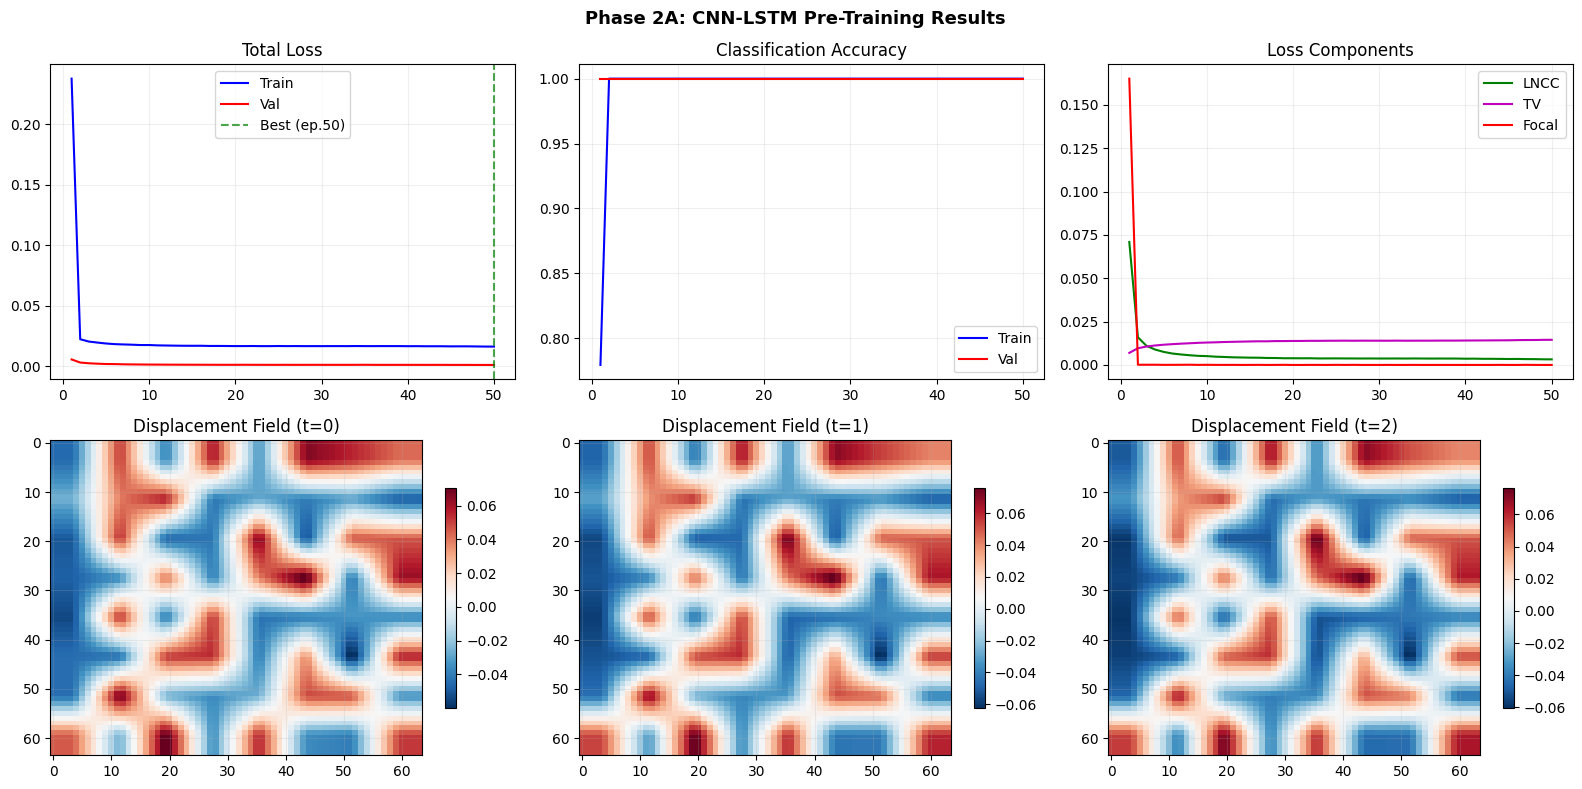

✅ Weights and history saved to /content/drive/My Drive/MIS_ETP/data/processed


In [14]:
# ── Training curves ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
epochs_x = list(range(1, len(history['train_loss']) + 1))

axes[0,0].plot(epochs_x, history['train_loss'], 'b-', label='Train')
axes[0,0].plot(epochs_x, history['val_loss'],   'r-', label='Val')
axes[0,0].axvline(best_epoch, ls='--', color='green', alpha=0.7, label=f'Best (ep.{best_epoch})')
axes[0,0].set_title('Total Loss'); axes[0,0].legend(); axes[0,0].grid(True, alpha=0.3)

axes[0,1].plot(epochs_x, history['train_acc'], 'b-', label='Train')
axes[0,1].plot(epochs_x, history['val_acc'],   'r-', label='Val')
axes[0,1].set_title('Classification Accuracy'); axes[0,1].legend(); axes[0,1].grid(True, alpha=0.3)

axes[0,2].plot(epochs_x, history['lncc'],  'g-',  label='LNCC')
axes[0,2].plot(epochs_x, history['tv'],    'm-',  label='TV')
axes[0,2].plot(epochs_x, history['focal'], 'r-',  label='Focal')
axes[0,2].set_title('Loss Components'); axes[0,2].legend(); axes[0,2].grid(True, alpha=0.3)

# Visualize final displacement fields
model.eval()
with torch.no_grad():
    # ✅ NEW — uses a real validation sample
    x_demo, _ = next(iter(val_loader))
    x_demo = x_demo[:1].to(DEVICE)
    _, disp_demo = model(x_demo)

disp_np = disp_demo[0].cpu().numpy()   # (T, H, W)
for i, ax in enumerate(axes[1, :]):
    t = i * (disp_np.shape[0] // 3)
    im = ax.imshow(disp_np[t], cmap='RdBu_r', aspect='auto')
    ax.set_title(f'Displacement Field (t={t})')
    plt.colorbar(im, ax=ax, shrink=0.7)

for ax in axes.flat:
    if ax.has_data(): ax.set_xlabel(''); ax.grid(True, alpha=0.2)
plt.suptitle('Phase 2A: CNN-LSTM Pre-Training Results', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(WEIGHTS_DIR, 'pretrain_curves.png'), dpi=150)
plt.show()

# ── Save final weights + history ─────────────────────────────────────────────
torch.save(model.state_dict(),
           os.path.join(WEIGHTS_DIR, 'cnn_lstm_pretrained_final.pth'))
with open(os.path.join(WEIGHTS_DIR, 'pretrain_history.json'), 'w') as f:
    json.dump(history, f, indent=2)

print('✅ Weights and history saved to', WEIGHTS_DIR)

## 6. Phase 2A Summary

| Component | Architecture | Purpose |
|-----------|-------------|----------|
| U-Net Encoder | Conv-BN-GELU × 4 + Global Pool | Extract speckle patterns per frame |
| Bi-LSTM | 2-layer, hidden=256 | Track tissue deformation over time |
| Classification Head | FC-GELU-Dropout × 3 | Output P(Benign/Precancerous/Malignant) |
| Displacement Head | FC + Bilinear upsample | Dense 2D strain map |
| LNCC Loss | Local window NCC | Acoustic tracking fidelity |
| TV Loss | Spatio-temporal gradients | Physical continuity regularization |
| Focal Loss | γ=2.0, α-weighted | Handle Precancerous class imbalance |
| ADMM | θ-step + z-step + u-step | Jointly optimize smooth + non-smooth terms |

**Output:** `backend/ml_engine/weights/cnn_lstm_pretrained_best.pth`  
→ Ready for **Phase 2B: Domain Adaptation** in `03_unsupervised_tuning.ipynb`